# Logistic Regression - Student Placement Prediction

## 1: Data Cleaning & Splitting


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
from sklearn.linear_model import LogisticRegression


In [2]:
# Load Dataset
candidates = [
    'student_placement_prediction_dataset_2026.csv',
    '../student_placement_prediction_dataset_2026.csv',
    'ml_source/student_placement_prediction_dataset_2026.csv',
]
dataset_path = next((p for p in candidates if os.path.exists(p)), 'student_placement_prediction_dataset_2026.csv')
df = pd.read_csv(dataset_path)
df.head()


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,...,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,...,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Placed,19.65
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,...,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,...,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,17.04
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,...,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,...,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Not Placed,0.00


In [3]:
df.columns


Index(['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier',
       'internships_count', 'projects_count', 'certifications_count',
       'coding_skill_score', 'aptitude_score', 'communication_skill_score',
       'logical_reasoning_score', 'hackathons_participated', 'github_repos',
       'linkedin_connections', 'mock_interview_score', 'attendance_percentage',
       'backlogs', 'extracurricular_score', 'leadership_score',
       'volunteer_experience', 'sleep_hours', 'study_hours_per_day',
       'placement_status', 'salary_package_lpa'],
      dtype='str')

In [4]:
df.describe()


,student_id,age,cgpa,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,...,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,sleep_hours,study_hours_per_day,salary_package_lpa
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,50000.500000,21.005740,7.496890,1.50223,3.001860,2.005150,69.825326,64.988108,67.960744,65.931696,...,4.005160,524.559110,69.989411,84.730169,0.497590,59.894049,54.937526,6.983319,3.523124,9.23698
std,28867.657797,1.999562,0.992834,1.22528,1.731764,1.416553,14.694618,14.844093,13.846636,14.826790,...,2.004897,274.993479,11.937257,9.416075,0.708434,19.549666,19.781197,1.468113,1.471248,8.45396
min,1.000000,18.000000,4.500000,0.00000,0.000000,0.000000,20.000000,20.000000,20.000000,20.000000,...,0.000000,50.000000,20.000000,50.000000,0.000000,0.000000,0.000000,3.000000,0.500000,0.00000
25%,25000.750000,19.000000,6.820000,1.00000,2.000000,1.000000,59.807945,54.894600,58.587535,55.940547,...,3.000000,287.000000,61.973172,78.325833,0.000000,46.538590,41.432390,6.000000,2.500000,0.00000
50%,50000.500000,21.000000,7.500000,1.00000,3.000000,2.000000,70.006250,65.011394,67.973221,66.003829,...,4.000000,523.000000,70.026665,85.018828,0.000000,60.079021,55.076210,7.000000,3.500000,14.60000
75%,75000.250000,23.000000,8.180000,2.00000,4.000000,3.000000,80.058762,75.079266,77.503749,76.113705,...,5.000000,764.000000,78.122083,91.782511,1.000000,73.549567,68.530115,8.000000,4.500000,16.87000
max,100000.000000,24.000000,10.000000,8.00000,13.000000,11.000000,100.000000,100.000000,100.000000,100.000000,...,16.000000,999.000000,100.000000,100.000000,6.000000,100.000000,100.000000,10.000000,10.000000,24.68000


In [5]:
df.shape


(100000, 26)

In [6]:
df.isnull().sum()


student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64

In [7]:
# Convert target to 0 and 1
if df['placement_status'].dtype == object or df['placement_status'].dtype == 'string':
    df['placement_status'] = df['placement_status'].map({'Not Placed': 0, 'Placed': 1})

# Feature Engineering (Domain Indicators)
df['academic_clearance_score'] = df['cgpa'] * np.exp(-0.30 * df['backlogs'])
df['has_zero_backlogs'] = (df['backlogs'] == 0).astype(int)
df['technical_mastery'] = 0.40 * df['coding_skill_score'] + 0.25 * df['aptitude_score'] + 0.20 * df['logical_reasoning_score'] + 0.15 * df['mock_interview_score']
df['experience_index'] = df['internships_count'] * 3.5 + df['projects_count'] * 1.5 + df['hackathons_participated'] * 1.5 + df['certifications_count'] * 0.8
df['placement_readiness_score'] = 0.35 * (df['academic_clearance_score'] * 10) + 0.35 * df['technical_mastery'] + 0.20 * np.clip(df['experience_index'] * 5, 0, 100) + 0.10 * df['attendance_percentage']

# Features and Target
X = df.drop(columns=['student_id', 'placement_status', 'salary_package_lpa'])
X = pd.get_dummies(X, drop_first=True)
y = df['placement_status']

print('Features:')
print(X.columns)

print('\nTarget:')
print(y.name)

print('\nTarget Class Distribution:\n')
print(y.value_counts())


Features:
Index(['age', 'cgpa', 'internships_count', 'projects_count',
       'certifications_count', 'coding_skill_score', 'aptitude_score',
       'communication_skill_score', 'logical_reasoning_score',
       'hackathons_participated', 'github_repos', 'linkedin_connections',
       'mock_interview_score', 'attendance_percentage', 'backlogs',
       'extracurricular_score', 'leadership_score', 'sleep_hours',
       'study_hours_per_day', 'academic_clearance_score', 'has_zero_backlogs',
       'technical_mastery', 'experience_index', 'placement_readiness_score',
       'gender_Male', 'branch_Civil', 'branch_ECE', 'branch_EEE', 'branch_IT',
       'branch_Mechanical', 'college_tier_Tier 2', 'college_tier_Tier 3',
       'volunteer_experience_Yes'],
      dtype='str')

Target:
placement_status

Target Class Distribution:

placement_status
1    54995
0    45005
Name: count, dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_25024\2105497808.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette=['#ef4444', '#10b981'])


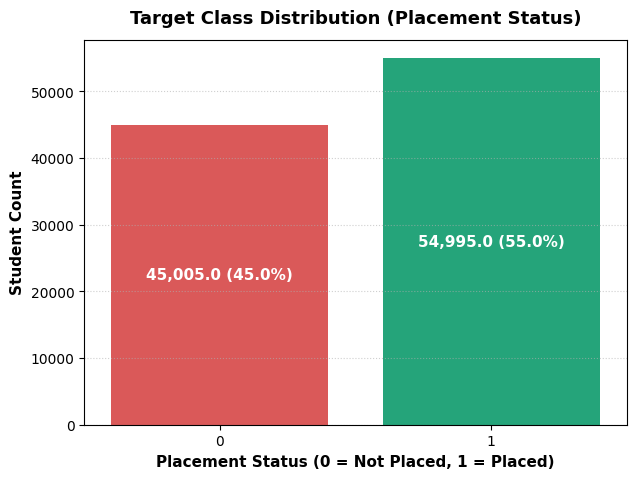

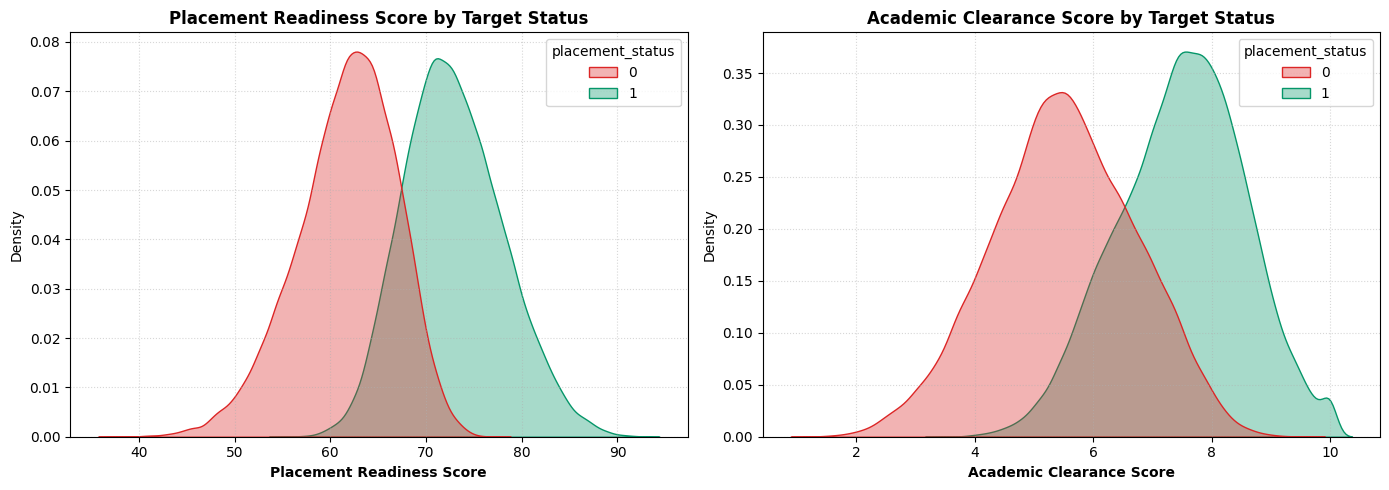

In [8]:
# EDA 1: Target Class Distribution with Percentages
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y, palette=['#ef4444', '#10b981'])
total = len(y)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:,} ({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')
plt.title('Target Class Distribution (Placement Status)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Placement Status (0 = Not Placed, 1 = Placed)', fontsize=11, fontweight='bold')
plt.ylabel('Student Count', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

# EDA 2: Key Engineered Feature Distributions by Placement Status
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=df, x='placement_readiness_score', hue='placement_status', common_norm=False, fill=True,
            palette=['#dc2626', '#059669'], alpha=0.35, ax=axes[0])
axes[0].set_title('Placement Readiness Score by Target Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Placement Readiness Score', fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.5)

sns.kdeplot(data=df, x='academic_clearance_score', hue='placement_status', common_norm=False, fill=True,
            palette=['#dc2626', '#059669'], alpha=0.35, ax=axes[1])
axes[1].set_title('Academic Clearance Score by Target Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Academic Clearance Score', fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


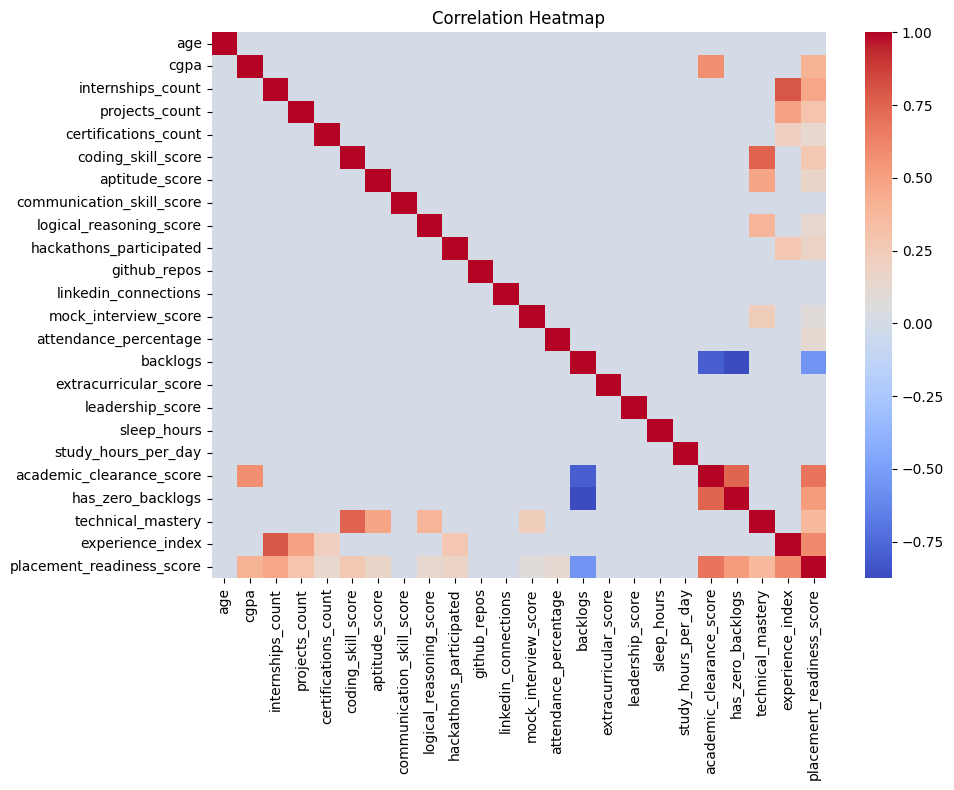

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.select_dtypes(include=[np.number]).corr(), annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Scaled Data:')
print(X_scaled)


Scaled Data:
[[ 1.49746565  0.03334894  2.03854087 ...  1.00090041 -0.65284608
   1.22380131]
 [-0.00287064  0.42616577 -0.40989218 ...  1.00090041 -0.65284608
  -0.81712611]
 [ 0.49724145  1.11107716 -1.22603652 ... -0.9991004  -0.65284608
  -0.81712611]
 ...
 [-0.50298274 -0.79257362  0.40625217 ...  1.00090041 -0.65284608
   1.22380131]
 [-1.00309484 -0.2889623   0.40625217 ...  1.00090041 -0.65284608
  -0.81712611]
 [ 0.49724145  1.09093271 -0.40989218 ... -0.9991004   1.53175463
   1.22380131]]


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training data shape:', X_train.shape)
print('Testing data shape:', X_test.shape)
print('Training labels:', y_train.shape)
print('Testing labels:', y_test.shape)


Training data shape: (80000, 33)
Testing data shape: (20000, 33)
Training labels: (80000,)
Testing labels: (20000,)


## 2: Logistic Regression Model


In [12]:
model = LogisticRegression(C=0.1, max_iter=2000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
results.head(15)


,Actual,Predicted
0,1,1
1,0,0
2,0,0
3,0,0
4,0,0
5,1,0
6,1,1
7,1,1
8,0,0
9,0,0


Accuracy: 94.05 %

Classification Report:

              precision    recall  f1-score   support

  Not Placed       0.93      0.93      0.93      9001
      Placed       0.95      0.95      0.95     10999

    accuracy                           0.94     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.94      0.94      0.94     20000



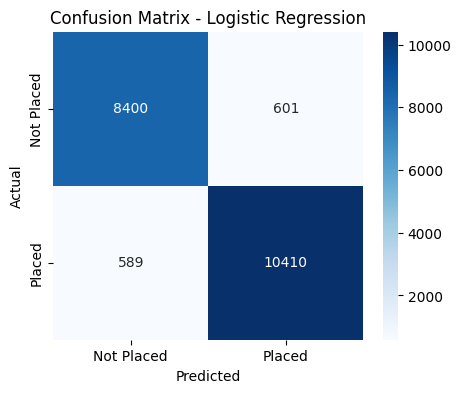

In [13]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', round(accuracy * 100, 2), '%')

print('\nClassification Report:\n')
print(classification_report(y_test, y_pred, target_names=['Not Placed', 'Placed']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Placed', 'Placed'], yticklabels=['Not Placed', 'Placed'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [14]:
# Predict on a sample student from test set
sample = X_test[0].reshape(1, -1)
prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0][1]

print('Predicted Class:', prediction)
print(f'Placement Probability: {probability * 100:.2f}%')
if prediction == 1:
    print('Placement Status: Placed')
else:
    print('Placement Status: Not Placed')


Predicted Class: 1
Placement Probability: 61.25%
Placement Status: Placed


In [15]:
# Save Model and Scaler
joblib.dump(model, 'logistic_regression.pkl')
joblib.dump(scaler, 'scaler.pkl')
print('Model saved as logistic_regression.pkl and scaler as scaler.pkl')


Model saved as logistic_regression.pkl and scaler as scaler.pkl


## 3: Logistic Regression Lines & Decision Boundary Visualizations

To analyze how **Logistic Regression** classifies students, we visualize:
1. **1D Sigmoid Probability Curve**: Models placement probability $P(\text{Placed}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$ as a function of Placement Readiness Score, showing the inflection threshold at $P = 0.5$.
2. **2D Decision Boundary & Probability Contours**:
   - **Top-2 Features** (`academic_clearance_score` vs `placement_readiness_score`): Linear decision boundary ($P=0.5$) with probability contour lines ($P=0.25, 0.5, 0.75$) and shaded confidence fields.
   - **PCA Projection (Full 33 Features)**: Linear separating line and probability gradients across the first two principal components.


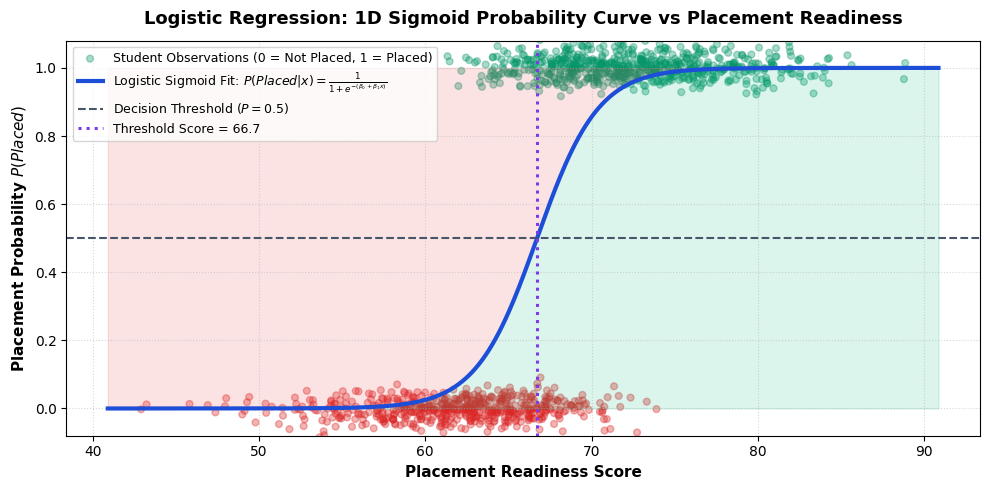

1D Logistic Regression Inflection Score: 66.72
Odds Ratio per unit increase in Readiness Score: 1.723


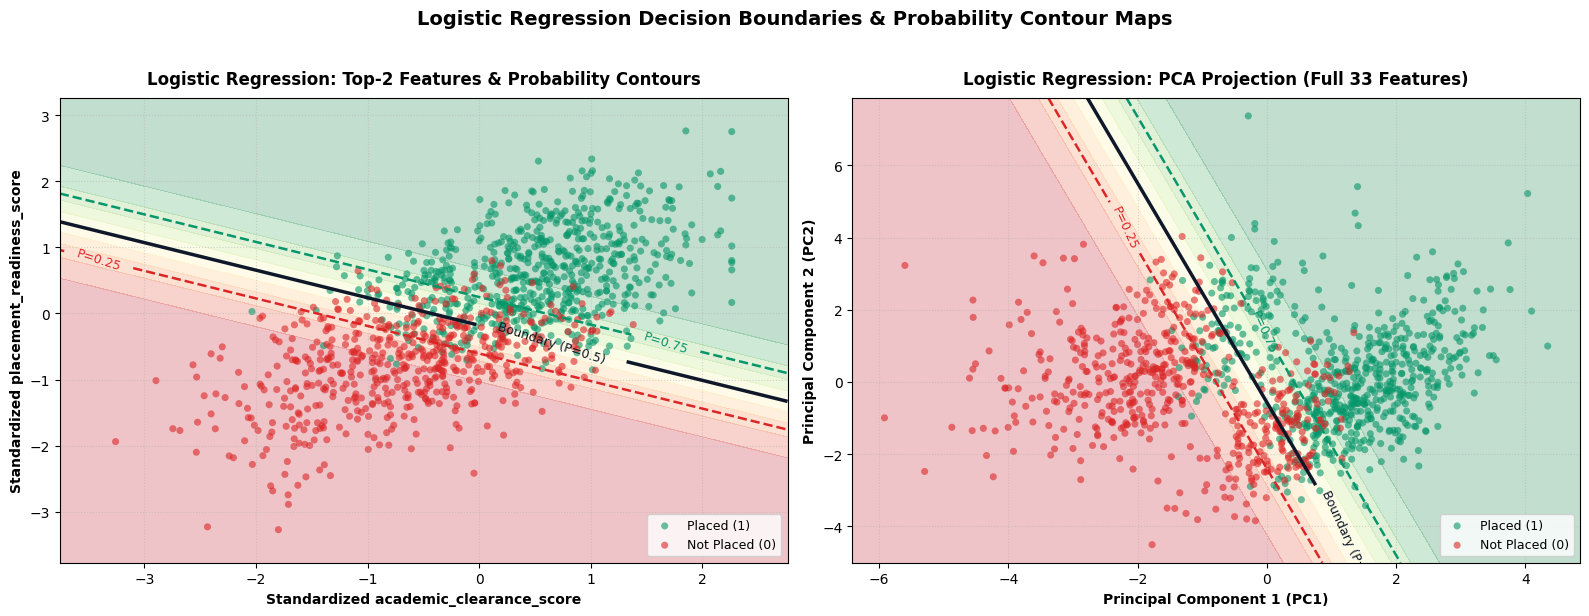

PCA explained variance ratio: PC1=0.0989, PC2=0.0709
Conclusion: The logistic regression decision boundary smoothly separates the two classes with clear probability margins.


In [16]:
from sklearn.decomposition import PCA

# ── Sample 1,200 points from test set for clear, fast visual rendering ──
np.random.seed(42)
vis_idx = np.random.choice(len(X_test), size=min(1200, len(X_test)), replace=False)
X_vis = X_test[vis_idx]
y_vis = y_test.iloc[vis_idx].values

# ══════════════════════════════════════════════════════════════════════════════
# 1. 1D Sigmoid Logistic Curve vs Placement Readiness Score
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 5))

# Extract unscaled readiness score for visual interpretability
x_readiness = df.iloc[y_test.index[vis_idx]]['placement_readiness_score'].values
lr_1d = LogisticRegression()
lr_1d.fit(x_readiness.reshape(-1, 1), y_vis)

x_grid = np.linspace(x_readiness.min() - 2, x_readiness.max() + 2, 500).reshape(-1, 1)
y_prob_1d = lr_1d.predict_proba(x_grid)[:, 1]

# Decision threshold where P = 0.5
threshold_score = -lr_1d.intercept_[0] / lr_1d.coef_[0][0]

# Scatter actual test student outcomes with slight jitter for visibility
jitter = np.random.normal(0, 0.03, size=len(y_vis))
ax.scatter(x_readiness, y_vis + jitter, c=np.where(y_vis == 1, '#059669', '#dc2626'),
           alpha=0.35, s=24, label='Student Observations (0 = Not Placed, 1 = Placed)')

# Plot Sigmoid Curve and Threshold lines
ax.plot(x_grid, y_prob_1d, color='#1d4ed8', linewidth=3, label=r'Logistic Sigmoid Fit: $P(Placed|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$')
ax.axhline(0.5, color='#475569', linestyle='--', linewidth=1.5, label='Decision Threshold ($P = 0.5$)')
ax.axvline(threshold_score, color='#7c3aed', linestyle=':', linewidth=2.2, label=f'Threshold Score = {threshold_score:.1f}')

# Shaded confidence regions
ax.fill_between(x_grid.ravel(), 0, y_prob_1d, color='#10b981', alpha=0.15)
ax.fill_between(x_grid.ravel(), y_prob_1d, 1, color='#ef4444', alpha=0.15)

ax.set_title('Logistic Regression: 1D Sigmoid Probability Curve vs Placement Readiness', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Placement Readiness Score', fontsize=11, fontweight='bold')
ax.set_ylabel('Placement Probability $P(Placed)$', fontsize=11, fontweight='bold')
ax.set_ylim(-0.08, 1.08)
ax.legend(loc='upper left', frameon=True, fontsize=9)
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"1D Logistic Regression Inflection Score: {threshold_score:.2f}")
print(f"Odds Ratio per unit increase in Readiness Score: {np.exp(lr_1d.coef_[0][0]):.3f}")

# ══════════════════════════════════════════════════════════════════════════════
# 2. 2D Decision Boundaries & Probability Contour Gradients
# ══════════════════════════════════════════════════════════════════════════════
feat1, feat2 = 'academic_clearance_score', 'placement_readiness_score'
i1 = list(X.columns).index(feat1)
i2 = list(X.columns).index(feat2)
X_pair = X_vis[:, [i1, i2]]

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_vis)

def plot_lr_decision_boundary(ax, X_2d, y_2d, xlabel, ylabel, title):
    lr_2d = LogisticRegression(C=0.1, random_state=42)
    lr_2d.fit(X_2d, y_2d)

    pad = 0.5
    x_min, x_max = X_2d[:, 0].min() - pad, X_2d[:, 0].max() + pad
    y_min, y_max = X_2d[:, 1].min() - pad, X_2d[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    probs = lr_2d.predict_proba(grid)[:, 1].reshape(xx.shape)

    # Shaded probability contour field
    cf = ax.contourf(xx, yy, probs, levels=np.linspace(0, 1, 11), cmap='RdYlGn', alpha=0.25)
    
    # Decision boundary line (P = 0.5) and confidence contours (P = 0.25, 0.75)
    cs = ax.contour(xx, yy, probs, levels=[0.25, 0.5, 0.75],
                    colors=['#dc2626', '#0f172a', '#059669'],
                    linewidths=[1.8, 2.5, 1.8], linestyles=['--', '-', '--'])
    ax.clabel(cs, inline=True, fontsize=9, fmt={0.25: 'P=0.25', 0.5: 'Boundary (P=0.5)', 0.75: 'P=0.75'})

    # Scatter points
    ax.scatter(X_2d[y_2d == 1, 0], X_2d[y_2d == 1, 1],
               c='#059669', label='Placed (1)', alpha=0.6, edgecolors='none', s=26)
    ax.scatter(X_2d[y_2d == 0, 0], X_2d[y_2d == 0, 1],
               c='#dc2626', label='Not Placed (0)', alpha=0.6, edgecolors='none', s=26)

    ax.set_xlabel(xlabel, fontsize=10, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.legend(loc='lower right', frameon=True, fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.5)
    return lr_2d

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_lr_decision_boundary(
    axes[0], X_pair, y_vis,
    xlabel=f'Standardized {feat1}',
    ylabel=f'Standardized {feat2}',
    title='Logistic Regression: Top-2 Features & Probability Contours'
)

plot_lr_decision_boundary(
    axes[1], X_pca, y_vis,
    xlabel='Principal Component 1 (PC1)',
    ylabel='Principal Component 2 (PC2)',
    title='Logistic Regression: PCA Projection (Full 33 Features)'
)

plt.suptitle('Logistic Regression Decision Boundaries & Probability Contour Maps',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"PCA explained variance ratio: PC1={pca.explained_variance_ratio_[0]:.4f}, PC2={pca.explained_variance_ratio_[1]:.4f}")
print("Conclusion: The logistic regression decision boundary smoothly separates the two classes with clear probability margins.")
